In [2]:
print("Proyecto 8 funcionando")



Proyecto 8 funcionando



# Proyecto 8: Energía de las olas frente a Pavones

**Curso:** Cálculo Diferencial e Integral

## Objetivo

Evaluar alternativas de convertidores de energía de las olas y baterías para suministrar electricidad a una boya marina.

Se analizan 960 registros horarios y se busca la combinación de menor costo que permita cubrir al menos el 99 % de las horas, tanto en condiciones normales como con una reducción del 20 % en la altura de las olas.

## Metodología

1. Lectura y validación de los datos originales.
2. Limpieza e interpolación de valores faltantes.
3. Integración numérica por trapecios y Simpson.
4. Cálculo del flujo energético del oleaje.
5. Simulación de convertidores y baterías.
6. Comparación de costos y disponibilidad.


In [3]:

"""Carga reproducible de los datos del Proyecto 8."""

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identificar la raíz del proyecto, incluso si Jupyter
# se ejecuta desde la subcarpeta notebooks.
carpeta_actual = Path.cwd().resolve()

if not (carpeta_actual / "P08_C-04_HERNANDEZ.xlsx").exists():
    carpeta_actual = carpeta_actual.parent

RUTA_PROYECTO = carpeta_actual
RUTA_EXCEL = RUTA_PROYECTO / "P08_C-04_HERNANDEZ.xlsx"

if not RUTA_EXCEL.is_file():
    raise FileNotFoundError(f"No se encontró el Excel: {RUTA_EXCEL}")

if str(RUTA_PROYECTO) not in sys.path:
    sys.path.insert(0, str(RUTA_PROYECTO))

from src.procesamiento_oleaje import preparar_energia_oleaje
from src.escenarios import comparar_escenarios, seleccionar_menor_costo

# Leer todas las hojas, sin modificar el archivo original.
hojas = pd.read_excel(RUTA_EXCEL, sheet_name=None)

print("Excel cargado correctamente.")
print("\nHojas disponibles:")

for nombre, datos in hojas.items():
    print(f"- {nombre}: {datos.shape}")


Excel cargado correctamente.

Hojas disponibles:
- Registros_oleaje: (960, 4)
- Muestra_elevacion: (400, 4)
- Opciones_convertidor: (3, 5)
- Opciones_bateria: (4, 3)
- Parametros: (6, 3)
- Diccionario: (19, 4)


Horas procesadas: 960
Alturas interpoladas: 4
Flujo medio (W/m): 9548.039


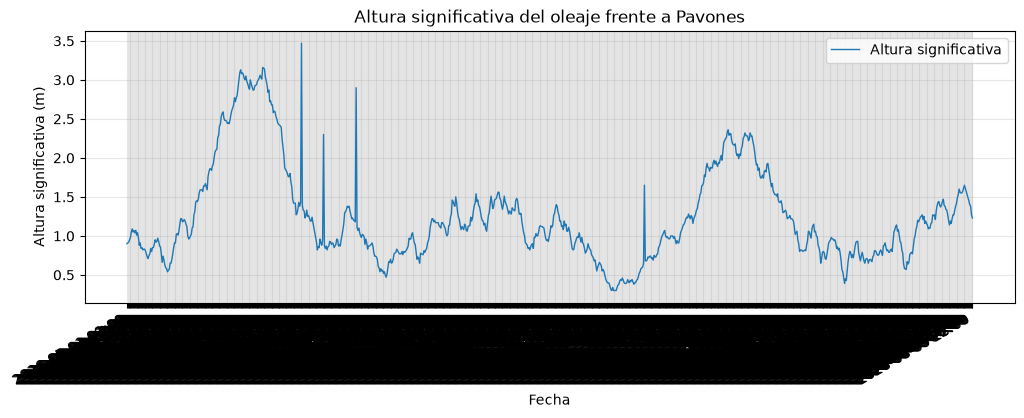

In [4]:

"""Prepara los registros y grafica la altura significativa."""

registros = preparar_energia_oleaje(
    hojas["Registros_oleaje"]
)

print("Horas procesadas:", len(registros))
print("Alturas interpoladas:", int(registros["altura_estimada"].sum()))
print(
    "Flujo medio (W/m):",
    round(registros["flujo_energia_w_m"].mean(), 3)
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    registros["fecha_hora"],
    registros["altura_significativa_m"],
    linewidth=1,
    label="Altura significativa"
)

ax.set_title("Altura significativa del oleaje frente a Pavones")
ax.set_xlabel("Fecha")
ax.set_ylabel("Altura significativa (m)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.show()



## Integración numérica y altura significativa

La varianza de elevación se aproxima mediante la integral:

$$
\sigma^2 = \frac{1}{T}\int_0^T \eta(t)^2\,dt
$$

La altura significativa del oleaje se calcula mediante:

$$
H_s = 4\sqrt{\sigma^2}
$$

Se comparan dos procedimientos:

- **Trapecio compuesto:** aproxima la integral utilizando trapecios.
- **Método híbrido:** aplica Simpson 1/3 en los primeros 198 subintervalos y trapecio en el último.

Cada muestra tiene 200 mediciones y 199 subintervalos. Por ello, no podemos aplicar Simpson 1/3 compuesto directamente a todos los intervalos.

La comparación permite comprobar la consistencia de las aproximaciones, pero una diferencia pequeña no demuestra por sí sola cuál método es más exacto.
